# JobStack Project 1: EDA (Person 4)

**Data:** `data/transformed/jobs_final.csv` (Person 2's output).
**Currently a 300-row development sample.** To switch to the full data, change only `DATA_PATH` in the first code cell.

Sections: 1. Overview & missingness | 2. Salary coverage | 3. Skill demand | 4. City patterns (Pakistan) | 5. Experience | 6. Findings log

In [1]:
from pathlib import Path
import ast
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

# Works whether Jupyter is started from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "transformed" / "jobs_final.csv"   # <- swap for full data later
FIG_DIR = ROOT / "reports" / "findings" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")

def parse_list(x):
    """extracted_skills is stored as text like "['Python', 'SQL']" in the CSV."""
    if isinstance(x, list):
        return x
    if pd.isna(x) or x == "":
        return []
    try:
        return ast.literal_eval(x)
    except (ValueError, SyntaxError):
        return []

df = pd.read_csv(DATA_PATH)
df["skills"] = df["extracted_skills"].apply(parse_list)
df["n_skills"] = df["skills"].str.len()
df["posted_at"] = pd.to_datetime(df["posted_at"], errors="coerce", utc=True)
print(f"Loaded {len(df):,} rows from {DATA_PATH.name}")

Loaded 300 rows from jobs_final.csv


## 1. Overview & missingness

In [2]:
print("Rows per source:")
display(df["source"].value_counts().to_frame("rows").assign(pct=lambda t: (100 * t.rows / len(df)).round(1)))

miss = (df.drop(columns=["skills", "n_skills"]).isna().mean() * 100).round(1).sort_values(ascending=False)
print("\n% missing per column:")
display(miss.to_frame("pct_missing"))

Rows per source:


,rows,pct
source,,
kaggle_pk,180,60.0
arbeitnow,115,38.3
remotive,5,1.7



% missing per column:


,pct_missing
currency,100.0
salary_max,100.0
salary_min,100.0
salary_text,99.0
candidate_location,98.3
source_url,60.0
experience,40.0
country,40.0
posted_at,38.3
employment_type,7.3


In [3]:
# Missingness by source: shows which fields only exist for some sources
cols = ["city", "experience", "employment_type", "company_name", "category", "salary_text"]
display((df.groupby("source")[cols].apply(lambda g: g.isna().mean() * 100)).round(1))

,city,experience,employment_type,company_name,category,salary_text
source,,,,,,
arbeitnow,13.0,100.0,19.1,0.0,6.1,100.0
kaggle_pk,0.0,0.0,0.0,5.0,0.0,100.0
remotive,100.0,100.0,0.0,0.0,0.0,40.0


## 2. Salary coverage
Salary is **never treated as zero**. We only report how much usable salary data exists.

In [4]:
has_numeric = df[["salary_min", "salary_max"]].notna().any(axis=1)
has_text = df["salary_text"].notna()
print(f"Numeric salary: {has_numeric.sum()} of {len(df)} ({100*has_numeric.mean():.1f}%)")
print(f"Free-text salary only: {(has_text & ~has_numeric).sum()} ({100*(has_text & ~has_numeric).mean():.1f}%)")
print(f"No salary info: {(~has_numeric & ~has_text).sum()} ({100*(~has_numeric & ~has_text).mean():.1f}%)")
print("\nConclusion: salary analysis is not possible with this data unless a better source is added.")

Numeric salary: 0 of 300 (0.0%)
Free-text salary only: 3 (1.0%)
No salary info: 297 (99.0%)

Conclusion: salary analysis is not possible with this data unless a better source is added.


## 3. Skill demand
Percentages are of postings in the group, not of total skill mentions.

In [5]:
print(f"Postings with at least one extracted skill: {(df.n_skills > 0).mean()*100:.1f}%")
print("Skills per posting by source (mean):")
display(df.groupby("source")["n_skills"].mean().round(2).to_frame("mean_skills"))

Postings with at least one extracted skill: 38.0%
Skills per posting by source (mean):


,mean_skills
source,
arbeitnow,1.46
kaggle_pk,0.24
remotive,4.40


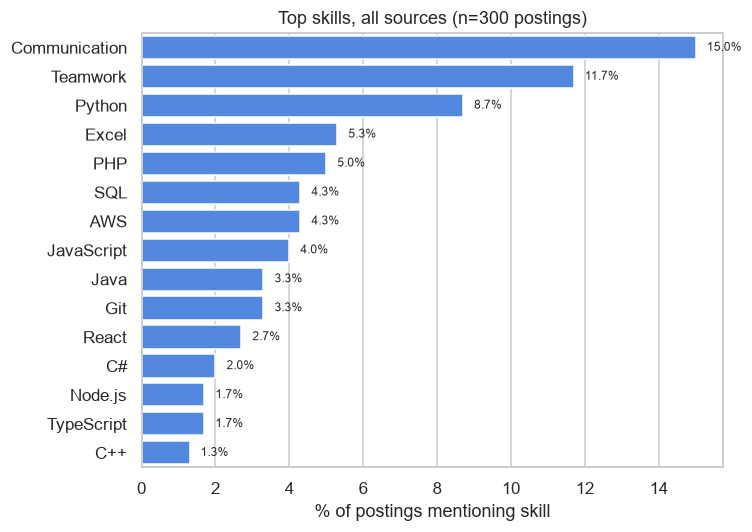

In [6]:
def skill_demand(frame, top=15):
    n = len(frame)
    counts = frame.explode("skills")["skills"].value_counts().head(top)
    return (counts / n * 100).round(1), n

def plot_skills(frame, title, fname, top=15):
    pct, n = skill_demand(frame, top)
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.barplot(x=pct.values, y=pct.index, color="#3b82f6", ax=ax)
    ax.set_xlabel("% of postings mentioning skill")
    ax.set_ylabel("")
    ax.set_title(f"{title} (n={n} postings)")
    for i, v in enumerate(pct.values):
        ax.text(v + 0.3, i, f"{v}%", va="center", fontsize=8)
    save_fig(fname)
    plt.show()

plot_skills(df, "Top skills, all sources", "top_skills_all")

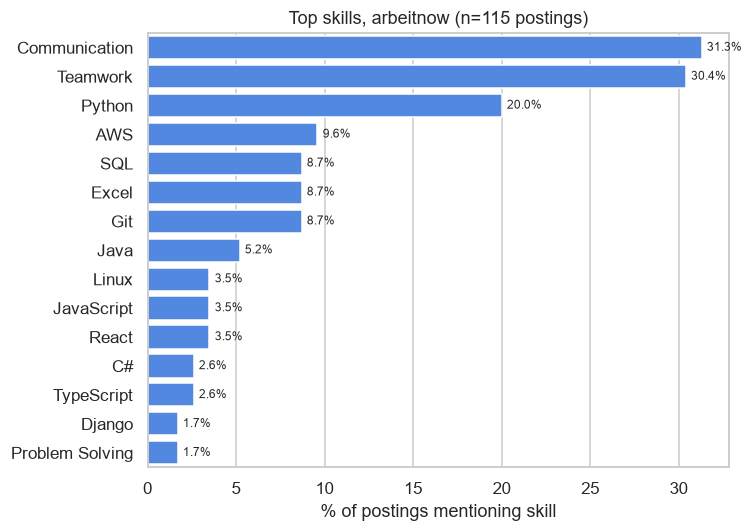

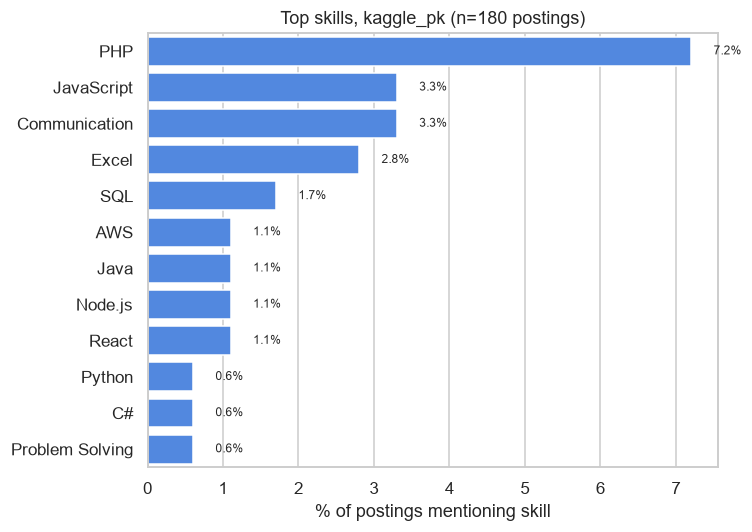

Skipping remotive: only 5 rows


In [7]:
# Same chart, per source: sources describe very different job markets, so compare separately
for src, g in df.groupby("source"):
    if len(g) >= 30:   # skip tiny groups (e.g. remotive in the sample)
        plot_skills(g, f"Top skills, {src}", f"top_skills_{src}")
    else:
        print(f"Skipping {src}: only {len(g)} rows")

## 4. City patterns (Pakistan only)
Only `kaggle_pk` is a Pakistan source. Note it covers all industries, not just tech.

In [ ]:
pk = df[df["source"] == "kaggle_pk"]
city_counts = pk["standardized_city"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=city_counts.values, y=city_counts.index, color="#10b981", ax=ax)
ax.set_title(f"Postings by city, Pakistan source (n={len(pk)})")
ax.set_xlabel("postings"); ax.set_ylabel("")
save_fig("postings_by_city_pk")
plt.show()

print("Top categories in the Pakistan source:")
display(pk["category"].value_counts().head(10).to_frame("postings"))

## 5. Experience (Pakistan source)
Raw text like `2 Years Job Exp.`. Parsed into a rough level for grouping.

In [ ]:
import re

def exp_level(s):
    if pd.isna(s): return None
    t = s.lower()
    if "fresh" in t or "< 1" in t or "less than" in t: return "0-1 yrs"
    m = re.search(r"(\d+)", t)
    if not m: return None
    y = int(m.group(1))
    return "0-1 yrs" if y < 1 else "1-3 yrs" if y <= 3 else "4-6 yrs" if y <= 6 else "7+ yrs"

pk = pk.assign(exp_level=pk["experience"].apply(exp_level))
order = ["0-1 yrs", "1-3 yrs", "4-6 yrs", "7+ yrs"]
print("Unparsed experience values:", pk["exp_level"].isna().sum(), "of", len(pk))
display(pk["exp_level"].value_counts().reindex(order).to_frame("postings"))

# Skills per posting by experience level
display(pk.groupby("exp_level")["n_skills"].agg(["count", "mean"]).reindex(order).round(2))

## 6. Findings log
Record each finding with: metric, sample size, filter, limitation. Update after the full data arrives.

| # | Finding | Metric | n | Filter | Limitation |
|---|---|---|---|---|---|
| 1 | Salary is almost entirely missing | % of postings with numeric salary | (fill) | all sources | Cannot analyze salary with current sources |
| 2 | | | | | |